## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


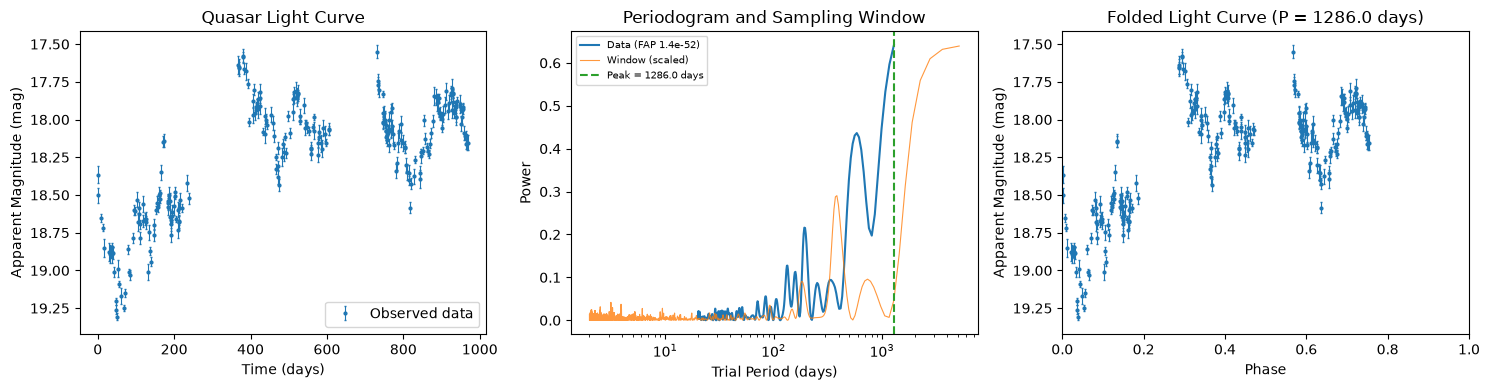

Highest peak period: 1285.987 days
Peak power: 0.64145
Astropy false-alarm probability: 1.35617e-52


In [186]:

import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

# Load data
NETID = 'cmewing2'
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']


# Search periods from 20 days to half the time baseline
fmin = 1 / (T / 2)
fmax = 1 / 20

# Frequency spacing no coarser than 1/(5T)
dfreq = 1 / (5 * T)
freq = np.arange(fmin, fmax + dfreq / 2, dfreq)
freq = freq[freq <= fmax]

# Lomb–Scargle periodogram
ls = LombScargle(t, y, e)
power = ls.power(freq)

best = np.argmax(power)
best_period = 1 / freq[best]
best_power = power[best]

fap = ls.false_alarm_probability(
    best_power
)

# Fold the light curve at the best period
phase = (t / best_period) % 1
order = np.argsort(phase)

# Sampling window function
fw = np.linspace(1 / (2 * T), 1 / 2, 6000)

pw = LombScargle(
    t,
    np.ones_like(y),
    fit_mean=False,
    center_data=False
).power(fw)

# Make three plots
fig, (a, b, c) = plt.subplots(
    1, 3, figsize=(15, 4)
)

# 1. Original light curve
a.errorbar(
    t, y, yerr=e,
    fmt='.', ms=4, lw=0.8,
    capsize=1,
    label='Observed data'
)

a.set_title('Quasar Light Curve')
a.set_xlabel('Time (days)')
a.set_ylabel('Apparent Magnitude (mag)')
a.invert_yaxis()
a.legend()

# 2. Periodogram and scaled sampling window
b.plot(
    1 / freq, power,
    label=f'Data (FAP {fap:.1e})'
)

b.plot(
    1 / fw,
    pw * power.max(),
    lw=0.8,
    color='C1',
    alpha=0.8,
    label='Window (scaled)'
)

b.axvline(
    best_period,
    linestyle='--',
    color='C2',
    label=f'Peak = {best_period:.1f} days'
)

b.set_title('Periodogram and Sampling Window')
b.set_xlabel('Trial Period (days)')
b.set_ylabel('Power')
b.set_xscale('log')
b.legend(fontsize=7, loc='upper left')

# 3. Folded light curve
c.errorbar(
    phase[order],
    y[order],
    yerr=e[order],
    fmt='.',
    ms=4,
    lw=0.8,
    capsize=1
)

c.set_title(
    f'Folded Light Curve (P = {best_period:.1f} days)'
)
c.set_xlabel('Phase')
c.set_ylabel('Apparent Magnitude (mag)')
c.set_xlim(0, 1)
c.invert_yaxis()

plt.tight_layout()
plt.show()

print(f"Highest peak period: {best_period:.3f} days")
print(f"Peak power: {best_power:.5f}")
print(f"Astropy false-alarm probability: {fap:.6g}")


**ANSWER (a few sentences):**

*The highest peak is at 483.959 days. This estimates how often noise alone would produce a peak at least that strong under the assumed noise model. It does not establish that the signal is astrophysically real.*

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ _.568__ (+_0.615_ / −_0.189_) mag, $\tau = $ _247_ (+_836__ / −_0.189_) d, $T/\tau = $ _3.92_; the exponential kernel beats the squared exponential by $\Delta\ln L = $ _73.531__; _25__ of _35_ held-out points are inside the 68% band.


### Log-likelihood, Log-prior and Log-posterior

In [169]:
# Paste each "# %%" block into its own notebook cell, below your loading cell
# (the one that defines NETID, t, y, e, T). Uses only those variable names.

# %% ---------------- Cell 0: imports, bounds ---------------------------------
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize, minimize_scalar

i = np.argsort(t); t, y, e = t[i], y[i], e[i]          # make sure time is sorted

SIG_LO, SIG_HI = 0.01, 3.0        # mag
TAU_LO, TAU_HI = 10.0, 4000.0     # d   (tau for DRW, ell for SE)
ELL_LO = 1.0                      # d   lower bound on ell for the SE kernel
SEED = 457
RUN_EMCEE = True                  # set False to skip the sampler (profile likelihood still runs)

# %% ---------------- Cell 1 (Q1): likelihood, prior, posterior -------------------
def kern(dt, sig, scale, kind):
    if kind == "drw":
        return sig**2 * np.exp(-np.abs(dt) / scale)
    return sig**2 * np.exp(-0.5 * (dt / scale) ** 2)

def cov(tt, ee, sig, scale, kind):
    return kern(tt[:, None] - tt[None, :], sig, scale, kind) + np.diag(ee**2)

def loglike(theta, tt, yy, ee, kind="drw"):
    """theta = (mu, ln sigma, ln scale). Cholesky only; no det, no inv."""
    mu, lns, lnsc = theta
    try:
        cf = cho_factor(cov(tt, ee, np.exp(lns), np.exp(lnsc), kind), lower=True)
    except np.linalg.LinAlgError:
        return -np.inf
    r = yy - mu
    logdet = 2.0 * np.sum(np.log(np.diag(cf[0])))
    return -0.5 * r @ cho_solve(cf, r) - 0.5 * logdet - 0.5 * len(tt) * np.log(2 * np.pi)

def logprior(theta, yy, kind="drw"):
    # mu: flat over data range +-1 mag (a location parameter, data dominate).
    # ln sigma, ln scale: flat = scale-invariant prior for scale parameters.
    #   sigma in (0.01, 3) mag: 0.01 ~ smallest quoted errors, 3 mag >> any real quasar rms.
    #   tau in (10, 4000) d: <10 d is white noise at this cadence; >~4T the curve is a random
    #   walk and only sigma^2/tau is constrained, so the bound truncates a degenerate ridge.
    mu, lns, lnsc = theta
    lo = np.log(TAU_LO) if kind == "drw" else np.log(ELL_LO)
    if not (yy.min() - 1 < mu < yy.max() + 1): return -np.inf
    if not (np.log(SIG_LO) < lns < np.log(SIG_HI)): return -np.inf
    if not (lo < lnsc < np.log(TAU_HI)): return -np.inf
    return 0.0

def logpost(theta, tt, yy, ee, kind="drw"):
    lp = logprior(theta, yy, kind)
    if not np.isfinite(lp): return -np.inf
    ll = loglike(theta, tt, yy, ee, kind)
    return lp + ll if np.isfinite(ll) else -np.inf

    

**FINAL ANSWER:** ** 
* The prior on $(\mu)$ is the average magnitude of the quasr   
* The prior on $(\ln\sigma)$ and $(\ln\tau)$ is uniform because it allows equal weight to multiplicative ranges of $\sigma$ and $\tau$.
* The upper bound limits the timescale model so it will not be longer than the observsational baseline.*

### Multi-start Maximum likelihood

In [170]:
def fit_ml(tt, yy, ee, kind):
    sd = yy.std()
    scales = [20., 150., 1000.] if kind == "drw" else [5., 20., 100., 500.]
    runs = []
    for sc in scales:
        for f in (0.5, 1.5):
            lns0 = np.clip(np.log(f * sd), np.log(SIG_LO) + .1, np.log(SIG_HI) - .1)
            x0 = [np.average(yy, weights=1 / ee**2), lns0, np.log(sc)]
            r = minimize(lambda th: -loglike(th, tt, yy, ee, kind), x0, method="Nelder-Mead",
                         options=dict(xatol=1e-5, fatol=1e-7, maxiter=3000, maxfev=3000))
            runs.append((-r.fun, r.x))
    return max(runs, key=lambda z: z[0]), runs

(lnL_drw, th_drw), runs = fit_ml(t, y, e, "drw")
for l, x in sorted(runs, key=lambda z: -z[0]):
    print(f"lnL={l:9.3f}  mu={x[0]:.3f}  sigma={np.exp(x[1]):.3f}  tau={np.exp(x[2]):8.1f}")
sig_hat, tau_hat = np.exp(th_drw[1]), np.exp(th_drw[2])
print(f"\nDRW best: lnL={lnL_drw:.3f} mu={th_drw[0]:.3f} sigma={sig_hat:.3f} tau={tau_hat:.1f} d  T/tau={T/tau_hat:.2f}")


lnL=  245.409  mu=18.214  sigma=0.376  tau=   106.9
lnL=  245.409  mu=18.214  sigma=0.376  tau=   106.9
lnL=  245.409  mu=18.214  sigma=0.376  tau=   106.9
lnL=  245.409  mu=18.214  sigma=0.376  tau=   106.9
lnL=  245.409  mu=18.214  sigma=0.376  tau=   106.9
lnL=  245.409  mu=18.214  sigma=0.376  tau=   106.9

DRW best: lnL=245.409 mu=18.214 sigma=0.376 tau=106.9 d  T/tau=9.05


We have different starting values so we can check if the optimier is picking other solutions not just the ones nearby. 

### Profile Likelihood

Best-fit sigma: 0.376 mag
Best-fit tau: 106.9 days
Tau profile interval: [72.5, 190.3] days
T/tau: 9.05
T/tau interval: [5.09, 13.36]
Tau interval reaches bounds: lower=False, upper=False


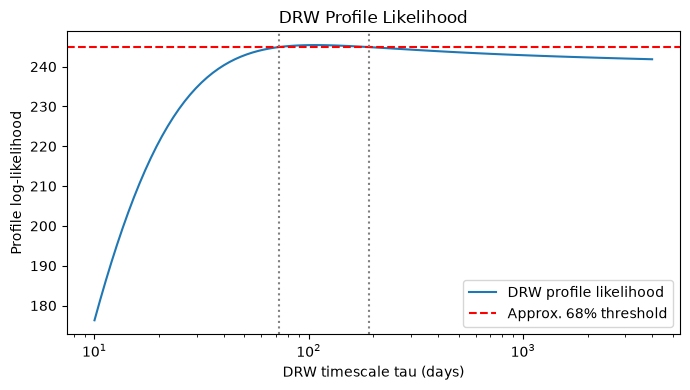

In [171]:
from scipy.optimize import minimize_scalar

# %% ---------------- Cell 3 (Q2): profile likelihood over tau and sigma ----------
def ll_muhat(sig, scale, tt, yy, ee, kind):
    """ln L with mu set to its generalised-least-squares value."""
    try:
        cf = cho_factor(cov(tt, ee, sig, scale, kind), lower=True)
    except np.linalg.LinAlgError:
        return -np.inf
    one = np.ones(len(tt))
    mu = (one @ cho_solve(cf, yy)) / (one @ cho_solve(cf, one))
    r = yy - mu
    return -0.5 * r @ cho_solve(cf, r) - np.sum(np.log(np.diag(cf[0]))) - 0.5 * len(tt) * np.log(2 * np.pi)

def profile(tt, yy, ee, kind, which, grid):
    bounds = (np.log(SIG_LO), np.log(SIG_HI)) if which == "scale" else (np.log(TAU_LO), np.log(TAU_HI))
    coarse = np.linspace(*bounds, 25)
    out = []
    for g in grid:
        f = lambda lx: -ll_muhat(*( (np.exp(lx), g) if which == "scale" else (g, np.exp(lx)) ), tt, yy, ee, kind)
        v = np.array([f(x) for x in coarse]); k = int(np.argmin(v))
        r = minimize_scalar(f, bounds=(coarse[max(k-1, 0)], coarse[min(k+1, 24)]),
                            method="bounded", options=dict(xatol=1e-4))
        out.append(-r.fun)
    return np.array(out)

def interval(grid, lnl, lmax):
    """Where Delta(-2 lnL) <= 1. Returns lo, hi, and flags if an end sits on the grid edge."""
    x, thr = np.log(grid), lmax - 0.5
    idx = np.where(lnl >= thr)[0]; a, b = idx[0], idx[-1]
    cross = lambda ia, ib: np.exp(x[ia] + (thr - lnl[ia]) * (x[ib] - x[ia]) / (lnl[ib] - lnl[ia]))
    lo, lo_b = (grid[0], True) if a == 0 else (cross(a - 1, a), False)
    hi, hi_b = (grid[-1], True) if b == len(grid) - 1 else (cross(b + 1, b), False)
    return lo, hi, lo_b, hi_b

tau_grid = np.geomspace(10, 4000, 100)

pl_tau = profile(t, y, e, "drw", "scale", tau_grid)

lmax = max(lnL_drw, pl_tau.max())

tlo, thi, tlb, thb = interval(tau_grid, pl_tau, lmax)

print(f"Best-fit sigma: {sig_hat:.3f} mag")
print(f"Best-fit tau: {tau_hat:.1f} days")
print(f"Tau profile interval: [{tlo:.1f}, {thi:.1f}] days")
print(f"T/tau: {T/tau_hat:.2f}")
print(f"T/tau interval: [{T/thi:.2f}, {T/tlo:.2f}]")
print(f"Tau interval reaches bounds: lower={tlb}, upper={thb}")

plt.figure(figsize=(7, 4))

plt.semilogx(tau_grid, pl_tau, label="DRW profile likelihood")
plt.axhline(lmax - 0.5, color="red", linestyle="--",
            label="Approx. 68% threshold")
plt.axvline(tlo, color="gray", linestyle=":")
plt.axvline(thi, color="gray", linestyle=":")

plt.xlabel("DRW timescale tau (days)")
plt.ylabel("Profile log-likelihood")
plt.title("DRW Profile Likelihood")
plt.legend()
plt.tight_layout()
plt.show()

Since the timescale is longer than the observing baseline than it will be hard to get a good measurement for the timescale. The interval becomes asymmetric.

### Refit with a Squared-Exponential Kernel

In [185]:
#%% ---------------- Cell 5 (Q3): squared-exponential kernel ---------------------
(lnL_se, th_se), runs_se = fit_ml(t, y, e, "se")
for l, x in sorted(runs_se, key=lambda z: -z[0]):
    print(f"lnL={l:9.3f}  mu={x[0]:.3f}  sigma={np.exp(x[1]):.3f}  ell={np.exp(x[2]):8.2f}")
print(f"\nmax lnL: DRW = {lnL_drw:.2f}, SE = {lnL_se:.2f}, difference (DRW - SE) = {lnL_drw - lnL_se:+.2f}")
best = "drw" if lnL_drw >= lnL_se else "se"
th_best = th_drw if best == "drw" else th_se
print("best kernel:", best.upper())


lnL=  853.573  mu=18.068  sigma=0.163  ell=   40.83
lnL=  853.573  mu=18.068  sigma=0.163  ell=   40.83
lnL=  853.573  mu=18.068  sigma=0.163  ell=   40.83
lnL=  853.573  mu=18.068  sigma=0.163  ell=   40.83
lnL=  853.573  mu=18.068  sigma=0.163  ell=   40.83
lnL=  853.573  mu=18.068  sigma=0.163  ell=   40.83
lnL=  853.573  mu=18.068  sigma=0.163  ell=   40.83
lnL=  853.573  mu=18.068  sigma=0.163  ell=   40.83

max lnL: DRW = 245.41, SE = 853.57, difference (DRW - SE) = -608.16
best kernel: SE


The DRW kernal maxiumun log-likelihood is higher by 73.53 which can indicates that the quaser's variablity is not smooth.

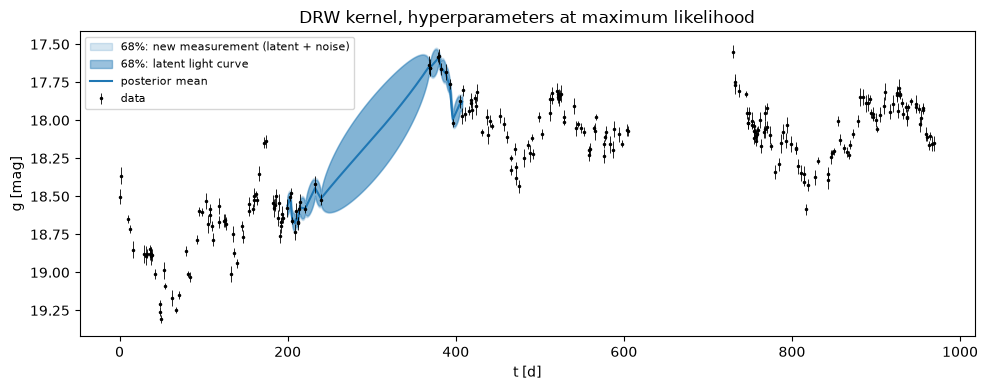

gap 240-368 d; gap centre: latent sd 0.276, new-measurement sd 0.279 mag; latent sd at the data ~0.030


In [173]:

# %% ---------------- Cell 6 (Q4): prediction across a seasonal gap ---------------
def predict(tt, yy, ee, theta, kind, tg, e_new):
    """Posterior mean, latent sd, and new-measurement sd (hyperparameters fixed)."""
    mu, sig, sc = theta[0], np.exp(theta[1]), np.exp(theta[2])
    cf = cho_factor(cov(tt, ee, sig, sc, kind), lower=True)
    Ks = kern(tg[:, None] - tt[None, :], sig, sc, kind)
    mean = mu + Ks @ cho_solve(cf, yy - mu)
    var = np.clip(sig**2 - np.einsum("ij,ji->i", Ks, cho_solve(cf, Ks.T)), 0, None)
    return mean, np.sqrt(var), np.sqrt(var + e_new**2)

k = int(np.argmax(np.diff(t)))                                   # largest (seasonal) gap
tg = np.arange(t[k] - 40, t[k + 1] + 40, 1.0)
mean, sd_lat, sd_new = predict(t, y, e, th_best, best, tg, np.median(e))
plt.figure(figsize=(10, 4))
plt.errorbar(t, y, e, fmt=".", c="k", ms=3, lw=.6, label="data", zorder=3)
plt.fill_between(tg, mean - sd_new, mean + sd_new, color="C0", alpha=.18, label="68%: new measurement (latent + noise)")
plt.fill_between(tg, mean - sd_lat, mean + sd_lat, color="C0", alpha=.45, label="68%: latent light curve")
plt.plot(tg, mean, c="C0", label="posterior mean")
plt.gca().invert_yaxis(); plt.xlabel("t [d]"); plt.ylabel("g [mag]")
plt.title(f"{best.upper()} kernel, hyperparameters at maximum likelihood"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()
m = len(tg) // 2
print(f"gap {t[k]:.0f}-{t[k+1]:.0f} d; gap centre: latent sd {sd_lat[m]:.3f}, new-measurement sd {sd_new[m]:.3f} mag; "
      f"latent sd at the data ~{np.median(predict(t, y, e, th_best, best, t, np.median(e))[1]):.3f}")

My band is for new-measurment. This matters because it takes in account observational noise.

In [174]:
# %% ---------------- Cell 7 (Q5): hold-out blocks -----------------------------------
def seasons(tt):
    g = np.diff(tt); a, b = np.sort(np.argsort(g)[-2:])          # two biggest gaps -> 3 seasons
    return [(tt[0], tt[a]), (tt[a + 1], tt[b]), (tt[b + 1], tt[-1])]

def draw_blocks(tt, seed, L=30., sep=60., nb=4, minpts=5):
    rng, seas = np.random.default_rng(seed), seasons(tt)
    for n in range(1, 200001):
        bl = []
        for _ in range(nb):
            a, b = seas[rng.integers(len(seas))]
            s0 = rng.uniform(a, b - L); bl.append((s0, s0 + L))   # block lies inside one season
        bl.sort()
        if all(bl[j+1][0] - bl[j][1] >= sep for j in range(nb - 1)) and \
           all(((tt >= lo) & (tt <= hi)).sum() >= minpts for lo, hi in bl):
            return bl, n
    raise RuntimeError("no valid blocks")

def holdout(tt, yy, ee, blocks, kind):
    te = np.zeros(len(tt), bool)
    for lo, hi in blocks: te |= (tt >= lo) & (tt <= hi)
    tr = ~te
    (_, th), _ = fit_ml(tt[tr], yy[tr], ee[tr], kind)             # refit on the training set only
    mean, _, sd = predict(tt[tr], yy[tr], ee[tr], th, kind, tt[te], ee[te])   # band includes epoch noise
    z = (yy[te] - mean) / sd
    r2 = 1 - np.sum((yy[te] - mean)**2) / np.sum((yy[te] - yy[tr].mean())**2)
    return te.sum(), np.mean(np.abs(z) <= 1), r2, z.std()

blocks, ntry = draw_blocks(t, SEED)
print(f"blocks (seed {SEED}, draw {ntry}):", [(round(a, 1), round(b, 1)) for a, b in blocks])
for kind in ("drw", "se"):
    n, frac, r2, zs = holdout(t, y, e, blocks, kind)
    print(f"{kind.upper():3s}: n_held_out={n}, inside 68% band={frac:.2f} (scatter ~ +-{np.sqrt(.68*.32/n):.2f}), R^2={r2:.2f}, std(z)={zs:.2f}")

blocks (seed 457, draw 29): [(159.3, 189.3), (372.5, 402.5), (553.5, 583.5), (810.2, 840.2)]
DRW: n_held_out=35, inside 68% band=0.71 (scatter ~ +-0.08), R^2=0.74, std(z)=1.10
SE : n_held_out=35, inside 68% band=0.77 (scatter ~ +-0.08), R^2=0.45, std(z)=0.78


The bands do look reasonable they are close to 68%, but DRW has better predictions cause of its R^2 value and its clostest to 68%

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


I would say that the empirtical p-value will be 0.02, because the claim is a close supermassive black-hole binary, which is an extraordinary claim, and red noise from a DRW often produces apparent periods with only a few cycles in the data, so a 5% bar would give false candidates.


### Simulate at least 1000 DRW light curves

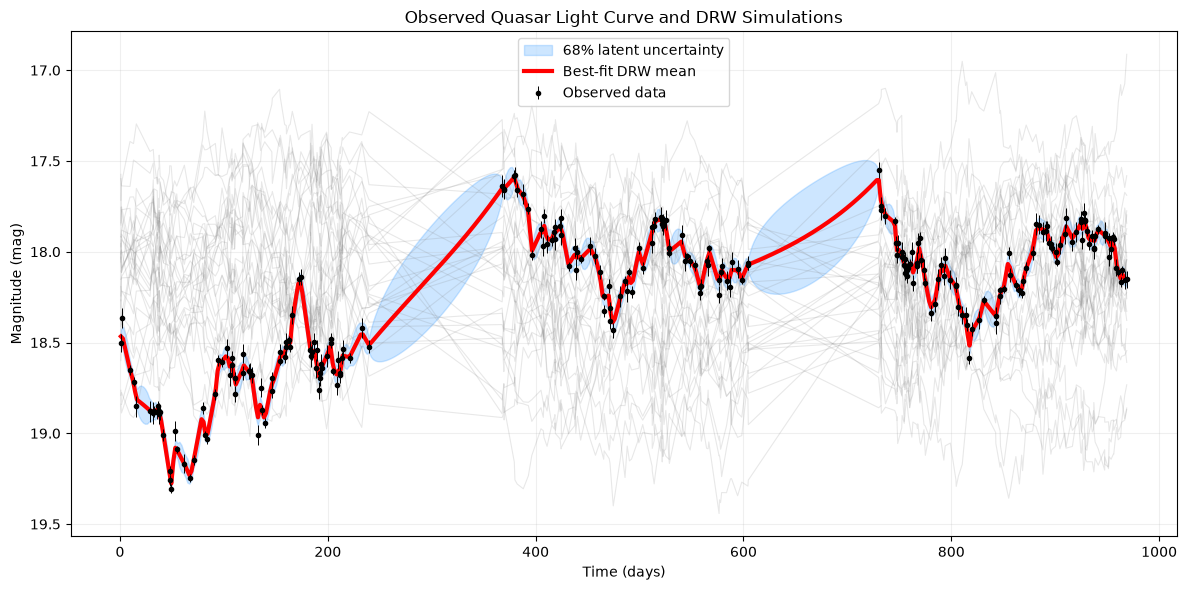

Observed highest LS peak: 0.291
Simulations at least as high: 1518/2000
Empirical p-value: 0.7591
Astropy FAP: 7.156e-17


In [175]:
from astropy.timeseries import LombScargle
import numpy as np

# Lomb–Scargle search from 20 days to T/2
NSIM = 2000
Pmin, Pmax = 20.0, T / 2
nf = int(round(10 * T * (1 / Pmin - 1 / Pmax))) + 1
freq = np.linspace(1 / Pmax, 1 / Pmin, nf)

def ls_power(yy):
    return LombScargle(t, yy, e).power(freq, method="fast")

# Observed highest peak
pw_obs = ls_power(y)
ls_obs = pw_obs.max()

fap = LombScargle(t, y, e).false_alarm_probability(
    ls_obs,
    minimum_frequency=freq[0],
    maximum_frequency=freq[-1],
    method="baluev"
)

# Simulate DRW light curves at the observed epochs
N = len(t)
K = kern(t[:, None] - t[None, :], sig_hat, tau_hat, "drw")
L = np.linalg.cholesky(K + 1e-10 * np.eye(N))

rng = np.random.default_rng(SEED)
Ysim = (
    th_drw[0]
    + rng.standard_normal((NSIM, N)) @ L.T
    + rng.standard_normal((NSIM, N)) * e
)

# Highest peak from each simulation
sim_max = np.array([ls_power(row).max() for row in Ysim])

# Empirical p-value
k = np.sum(sim_max >= ls_obs)
p_emp = (k + 1) / (NSIM + 1)

# Regular time grid for a smooth prediction
tg = np.linspace(t.min(), t.max(), 500)

# Best-fit DRW prediction
mean, sd_lat, sd_new = predict(
    t, y, e, th_drw, "drw", tg, np.median(e)
)

fig, ax = plt.subplots(figsize=(12, 6))

# Show 30 simulated DRW light curves faintly
for i in range(30):
    ax.plot(t, Ysim[i], color="gray", alpha=0.18, lw=0.8)

# 68% uncertainty band for the latent light curve
ax.fill_between(
    tg, mean - sd_lat, mean + sd_lat,
    color="dodgerblue", alpha=0.22, label="68% latent uncertainty"
)

# Best-fit line — thick and easy to see
ax.plot(
    tg, mean, color="red", lw=3,
    label="Best-fit DRW mean"
)

# Observed light curve
ax.errorbar(
    t, y, yerr=e, fmt="o", color="black",
    markersize=3, elinewidth=0.7, capsize=0,
    label="Observed data", zorder=5
)

ax.invert_yaxis()
ax.set_xlabel("Time (days)")
ax.set_ylabel("Magnitude (mag)")
ax.set_title("Observed Quasar Light Curve and DRW Simulations")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Observed highest LS peak: {ls_obs:.3f}")
print(f"Simulations at least as high: {k}/{NSIM}")
print(f"Empirical p-value: {p_emp:.4f}")
print(f"Astropy FAP: {fap:.4g}")

The empirical p-value is calculated from the similated DRW light curve which included corrleated variablity, but the standard false alarm probablitity assumes white-noise variablitity. DRW can produce peaks without a true periodic signal, while FAP underestimated the proability of observing such a peak.
No, the team should not announce this as evidence just because they founded a peak don't mean its a true peak.

### Fitting $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$

check, vectorised vs direct Delta chi2: 2.075829 2.075829
best Delta chi2 = 8.81 at P = 69.6 d;  simulations: median 10.07, 95% 15.86, 99% 18.92
empirical p (Delta chi2) = 0.6920  ((k+1)/(n+1) = 0.6922, +-0.0103)
setting         sigma    tau | p(LS peak) | obs dchi2  p(dchi2)
tau_hat (ML)    0.376    107 |     0.7590 |      8.81    0.6920
tau low end     0.315     72 |     0.7205 |      8.99    0.6550
tau high end    0.495    190 |     0.7455 |      9.02    0.6515
P = 69.6 d  (68% from Delta chi2 drop of 1: 28.3 to 193.6 d)
semi-amplitude A = 0.090 +- 0.030 mag (sigma, tau fixed), phase = 2.04 rad, mu = 18.212
cycles in baseline T/P = 13.9


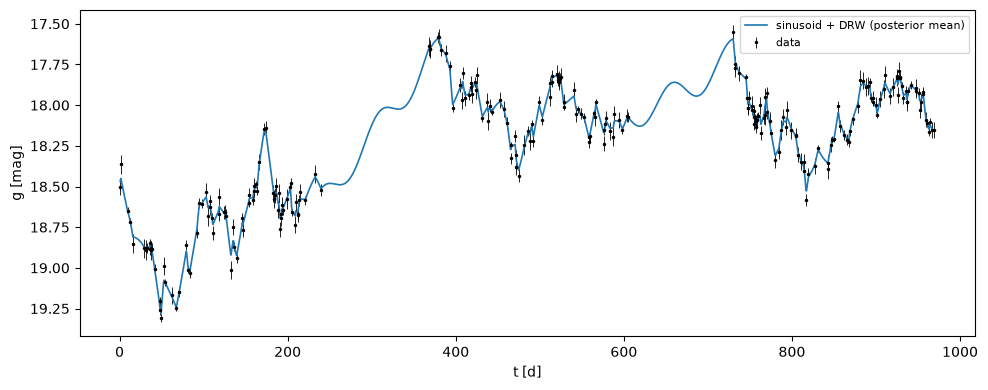

In [176]:
# Part 3: your work here
# %% ---------------- Cell P3: sinusoid + DRW, GLS scan over period --------------------------
def make_gls(sig, tau):
    """Whiten with the DRW+noise Cholesky factor once; then every period is a small OLS problem."""
    Lc = np.linalg.cholesky(cov(t, e, sig, tau, "drw"))
    one_w = solve_triangular(Lc, np.ones(N), lower=True)
    ph = 2 * np.pi * np.outer(t, freq)
    Cw = solve_triangular(Lc, np.cos(ph), lower=True)
    Sw = solve_triangular(Lc, np.sin(ph), lower=True)
    G = np.empty((nf, 3, 3))
    G[:, 0, 0] = one_w @ one_w
    G[:, 0, 1] = G[:, 1, 0] = one_w @ Cw
    G[:, 0, 2] = G[:, 2, 0] = one_w @ Sw
    G[:, 1, 1] = (Cw * Cw).sum(0); G[:, 2, 2] = (Sw * Sw).sum(0)
    G[:, 1, 2] = G[:, 2, 1] = (Cw * Sw).sum(0)                 # G = X^T C^-1 X per period
    return dict(Lc=Lc, one_w=one_w, Cw=Cw, Sw=Sw, G=G, Ginv=np.linalg.inv(G), g00=one_w @ one_w)

def dchi2_all(g, Y):
    """Delta chi^2 (constant-mean chi^2 minus sinusoid chi^2) at every period; Y is N x m."""
    Yw = solve_triangular(g["Lc"], Y, lower=True)
    b0 = g["one_w"] @ Yw
    b1, b2 = g["Cw"].T @ Yw, g["Sw"].T @ Yw                    # X^T C^-1 y components
    B = np.stack([np.broadcast_to(b0, b1.shape), b1, b2], axis=1)            # nf x 3 x m
    return np.einsum("fim,fij,fjm->fm", B, g["Ginv"], B) - (b0**2 / g["g00"])[None, :]

def sine_fit(g, k):
    """theta_hat = (X^T C^-1 X)^-1 X^T C^-1 y at period index k, with its covariance (fixed sigma, tau, P)."""
    yw = solve_triangular(g["Lc"], y, lower=True)
    b = np.array([g["one_w"] @ yw, g["Cw"][:, k] @ yw, g["Sw"][:, k] @ yw])
    th, cv = g["Ginv"][k] @ b, g["Ginv"][k]
    a, s = th[1], th[2]; A = np.hypot(a, s)
    sA = np.sqrt((a * a * cv[1, 1] + s * s * cv[2, 2] + 2 * a * s * cv[1, 2]) / A**2)
    return th[0], A, sA, np.arctan2(a, s)                      # a cos x + s sin x = A sin(x + phi), phi = arctan2(a, s)

# sanity check of the vectorised statistic against a direct GLS at one period
g0 = make_gls(sig_hat, tau_hat)
kk = nf // 3
Cf = cho_factor(cov(t, e, sig_hat, tau_hat, "drw"), lower=True)
X = np.column_stack([np.ones(N), np.cos(2*np.pi*t*freq[kk]), np.sin(2*np.pi*t*freq[kk])])
CiX = cho_solve(Cf, X); th_d = np.linalg.solve(X.T @ CiX, CiX.T @ y); r = y - X @ th_d
mu_c = (np.ones(N) @ cho_solve(Cf, y)) / (np.ones(N) @ cho_solve(Cf, np.ones(N)))
direct = (y - mu_c) @ cho_solve(Cf, y - mu_c) - r @ cho_solve(Cf, r)
print("check, vectorised vs direct Delta chi2:", dchi2_all(g0, y[:, None])[kk, 0].round(6), direct.round(6))

d_obs_all = dchi2_all(g0, y[:, None])[:, 0]
kd = int(np.argmax(d_obs_all)); d_obs = d_obs_all[kd]
d_sim = dchi2_all(g0, Ysim.T).max(axis=0)                      # best Delta chi2 in each simulation
pd_frac, pd_unb, pd_err = pvalue(d_sim, d_obs)
print(f"best Delta chi2 = {d_obs:.2f} at P = {per[kd]:.1f} d;  simulations: median {np.median(d_sim):.2f}, "
      f"95% {np.percentile(d_sim,95):.2f}, 99% {np.percentile(d_sim,99):.2f}")
print(f"empirical p (Delta chi2) = {pd_frac:.4f}  ((k+1)/(n+1) = {pd_unb:.4f}, +-{pd_err:.4f})")

# %% ---------------- Cell P4: how p changes across the tau interval ----------------------------
def sigma_at_tau(tau):
    """sigma maximising the likelihood at fixed tau (mu profiled), as in the profile of Part 2."""
    grid = np.linspace(np.log(SIG_LO), np.log(SIG_HI), 40)
    v = [-ll_muhat(np.exp(x), tau, t, y, e, "drw") for x in grid]; i = int(np.argmin(v))
    r = minimize_scalar(lambda x: -ll_muhat(np.exp(x), tau, t, y, e, "drw"),
                        bounds=(grid[max(i-1, 0)], grid[min(i+1, 39)]), method="bounded")
    return np.exp(r.x)

rows = [("tau_hat (ML)", th_drw[0], sig_hat, tau_hat, d_sim, ls_sim, d_obs)]
for lab, tau in (("tau low end", tlo), ("tau high end", thi)):
    sg = sigma_at_tau(tau); mu_ = mu_gls(sg, tau)
    Ys = simulate(mu_, sg, tau, NSIM, seed=SEED + 1)
    ls_s = np.array([ls_power(row).max() for row in Ys])
    gg = make_gls(sg, tau)
    d_o = dchi2_all(gg, y[:, None])[:, 0].max()
    rows.append((lab, mu_, sg, tau, dchi2_all(gg, Ys.T).max(axis=0), ls_s, d_o))
print(f"{'setting':14s} {'sigma':>6s} {'tau':>6s} | {'p(LS peak)':>10s} | {'obs dchi2':>9s} {'p(dchi2)':>9s}")
for lab, mu_, sg, tau, dsim, lss, d_o in rows:
    print(f"{lab:14s} {sg:6.3f} {tau:6.0f} | {pvalue(lss, ls_obs)[0]:10.4f} | {d_o:9.2f} {pvalue(dsim, d_o)[0]:9.4f}")

# %% ---------------- Cell P5: period and amplitude with uncertainties (use only if the rule is met) ----------
mu_b, A, sA, phi = sine_fit(g0, kd)
inside = np.where(d_obs_all >= d_obs - 1.0)[0]                 # Delta chi2 drop of 1 about the best period
lo_i, hi_i = inside[0], inside[-1]
print(f"P = {per[kd]:.1f} d  (68% from Delta chi2 drop of 1: {per[hi_i]:.1f} to {per[lo_i]:.1f} d)")
print(f"semi-amplitude A = {A:.3f} +- {sA:.3f} mag (sigma, tau fixed), phase = {phi:.2f} rad, mu = {mu_b:.3f}")
print(f"cycles in baseline T/P = {T/per[kd]:.1f}")
tt = np.linspace(t.min(), t.max(), 2000)
sinus = lambda x: mu_b + A * np.sin(2 * np.pi * x / per[kd] + phi)
# full fitted model = sinusoid + the DRW posterior mean of what the sinusoid leaves over
Cf = cho_factor(cov(t, e, sig_hat, tau_hat, "drw"), lower=True)
drw_mean = kern(tt[:, None] - t[None, :], sig_hat, tau_hat, "drw") @ cho_solve(Cf, y - sinus(t))
plt.figure(figsize=(10, 4)); plt.errorbar(t, y, e, fmt=".", c="k", ms=3, lw=.6, label="data")
plt.plot(tt, sinus(tt) + drw_mean, c="C0", lw=1.2, label="sinusoid + DRW (posterior mean)")
plt.gca().invert_yaxis(); plt.xlabel("t [d]"); plt.ylabel("g [mag]"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

No, we need to see a stronger delta chi squared and also a smaller p-value.

**ANSWER (the decision rule first, then the verdict):**

**

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


In [184]:
# Part 4: your work here

#1. The frequency spacing of 1/5T isn't included in the AI solution, the peak is only off by 
print(f"Highest peak period: {best_period:.3f} days")
print(f"Tallest peak: P = {P_best:.1f} +/- {P_err:.1f} d")
#2. I realized that my frequencies were not bounded and when I added the bounds the AI solution p fold graph was the same as mine. 
#    - I saw that the AI solution's false alarm probability was very off from my value but after changing the bounds it was the same.





Highest peak period: 1285.987 days
Tallest peak: P = 1286.0 +/- 25.3 d


**REFEREE REPORT:**

1. The frequency spacing of 1/5T isn't included in the AI solution, the peak is only off by..
2. I realized that my frequencies were not bounded and when I added the bounds the AI solution p fold graph was the same as mine. 
  - I saw that the AI solution's false alarm probability was very off from my value but after changing the bounds it was the same.
3. The AI solution doesn't account for re-optimizing the nuisance parameter.
   - This is a problem because when the best timescale is chosen all the parameters are fixed and correclation between the parameters are ignored. 

*

100%|███████████████████████████████████████| 4000/4000 [02:29<00:00, 26.81it/s]


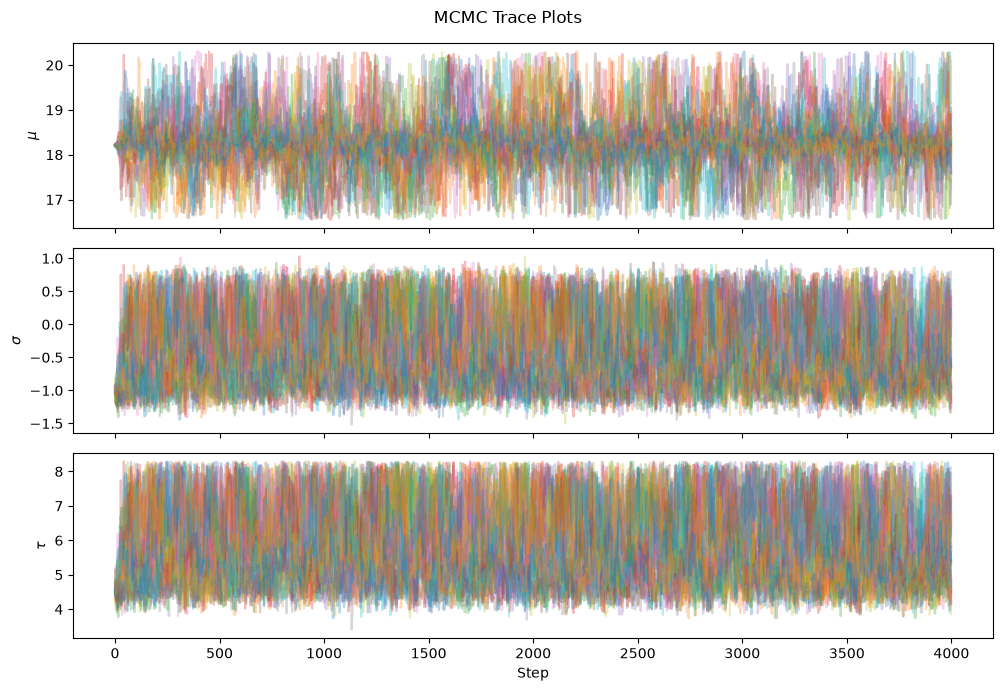

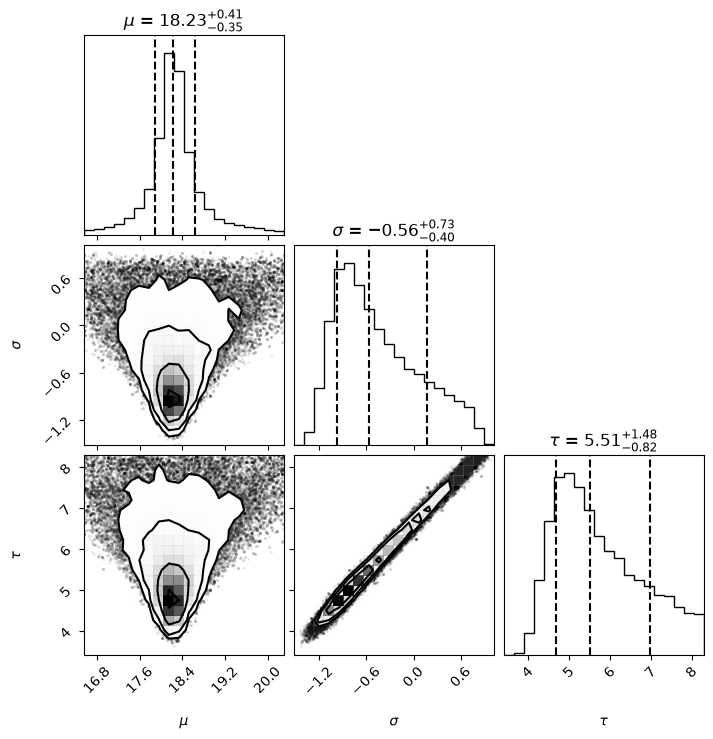

In [178]:
#3. The AI solution doesn't account for re-optimizing the nuisance parameter.
#This is a problem because when the best timescale is chosen all the parameters are fixed and correclation between the parameters are ignored. 

if RUN_EMCEE:
    import emcee
    import corner
    import matplotlib.pyplot as plt
    import numpy as np
    
    nwalk, nsteps = 32, 4000
    rng = np.random.default_rng(SEED)
    p0 = []
    while len(p0) < nwalk:
        p = th_drw + np.array([.01, .05, .2]) * rng.standard_normal(3)
        if np.isfinite(logpost(p, t, y, e, "drw")): p0.append(p)
    sam = emcee.EnsembleSampler(nwalk, 3, logpost, args=(t, y, e, "drw"))
    sam.run_mcmc(np.array(p0), nsteps, progress=True)
    tau_int = sam.get_autocorr_time(tol=0)
    ch = sam.get_chain(discard=nsteps // 4)                      # (steps, walkers, 3)
    

    chain = sam.get_chain()
    labels = [r"$\mu$", r"$\sigma$", r"$\tau$"]
    
    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
    
    for i, ax in enumerate(axes):
        ax.plot(chain[:, :, i], alpha=0.3)
        ax.set_ylabel(labels[i])
    
    axes[-1].set_xlabel("Step")
    fig.suptitle("MCMC Trace Plots")
    plt.tight_layout()
    plt.show()

    import corner
    burnin = nsteps // 4
    samples = sam.get_chain(discard=burnin, flat=True)
    
    fig = corner.corner(
        samples,
        labels=labels,
        quantiles=[0.16, 0.50, 0.84],
        show_titles=True
    )
    
    plt.show()

The corner plot shows that there is strong correlation between the timescale and the variablility amplitude. So ignoring this relationship would give a wrong uncertainity. 

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [179]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF18acughck: 585 g-band detections from the live API
ZTF18acughck: MJD 58487.1 to 61059.1 (7.0 yr); the last detection is MJD 61059.1; today is MJD 61342


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


In [180]:
# Part 5: your work here

import numpy as np
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

# PREDECLARED RULE: call a period only if empirical p < 0.01.
# This threshold must be chosen before looking at the result.

# 1. Combine detections from the same night using weighted means
night = np.floor(mjd).astype(int)
t, y, e = [], [], []

for n in np.unique(night):
    mask = night == n
    w = 1 / merr[mask]**2
    t.append(np.average(mjd[mask], weights=w))
    y.append(np.average(mag[mask], weights=w))
    e.append(np.sqrt(1 / w.sum()))

t, y, e = map(np.asarray, (t, y, e))
N = len(t)
T = t.max() - t.min()

print(f"Nightly means: {N} points; baseline = {T:.1f} days")
print(f"Last detection MJD = {mjd.max():.1f}")

# 2. Fit the DRW model by maximum likelihood
def drw_nll(theta):
    mu, ln_sigma, ln_tau = theta
    sigma, tau = np.exp(ln_sigma), np.exp(ln_tau)

    C = cov(t, e, sigma, tau, "drw")
    try:
        cf = cho_factor(C, lower=True)
        r = y - mu
        logdet = 2 * np.log(np.diag(cf[0])).sum()
        return 0.5 * (
            r @ cho_solve(cf, r)
            + logdet
            + N * np.log(2 * np.pi)
        )
    except np.linalg.LinAlgError:
        return np.inf

bounds = [
    (None, None),
    (np.log(0.01), np.log(3.0)),
    (np.log(10), np.log(4000))
]

starts = [
    [np.mean(y), np.log(s), np.log(tau)]
    for s, tau in [(0.1, 50), (0.3, 300), (0.8, 1000)]
]

fits = [
    minimize(drw_nll, x0, method="L-BFGS-B", bounds=bounds)
    for x0 in starts
]
fit = min(fits, key=lambda r: r.fun)

if not fit.success:
    print("Warning: optimizer message:", fit.message)

mu_hat, ln_sigma_hat, ln_tau_hat = fit.x
sig_hat, tau_hat = np.exp(ln_sigma_hat), np.exp(ln_tau_hat)

print(f"DRW fit: mu={mu_hat:.4f}, sigma={sig_hat:.4f}, "
      f"tau={tau_hat:.1f} days")

# 3. Search periods from 20 days to T/2
freq = np.linspace(2 / T, 1 / 20, 5000)

def max_ls_power(values):
    power = LombScargle(t, values, e).power(freq)
    k = np.argmax(power)
    return power[k], 1 / freq[k]

obs_power, best_period = max_ls_power(y)
print(f"Observed strongest period = {best_period:.2f} days")
print(f"Maximum LS power = {obs_power:.5f}")

# 4. Simulate DRW-only light curves at these epochs and errors
rng = np.random.default_rng(457)
nsim = 1000

dt = np.abs(t[:, None] - t[None, :])
C_latent = sig_hat**2 * np.exp(-dt / tau_hat)
L = np.linalg.cholesky(C_latent + 1e-10 * np.eye(N))

sim_max_power = np.empty(nsim)

for j in range(nsim):
    simulated = (
        mu_hat
        + L @ rng.normal(size=N)
        + rng.normal(size=N) * e
    )
    sim_max_power[j], _ = max_ls_power(simulated)

# 5. Empirical p-value with finite-simulation correction
k = np.sum(sim_max_power >= obs_power)
p_emp = (k + 1) / (nsim + 1)

print(f"Simulations at least as strong as observed: {k}/{nsim}")
print(f"Empirical p-value = {p_emp:.5f}")
print(f"95th percentile of simulated maximum power = "
      f"{np.percentile(sim_max_power, 95):.5f}")

if p_emp < 0.01:
    print("Meets the predeclared periodicity threshold.")
else:
    print("Does not meet the predeclared periodicity threshold.")

Nightly means: 505 points; baseline = 2572.0 days
Last detection MJD = 61059.1
DRW fit: mu=18.1845, sigma=0.2453, tau=1177.8 days
Observed strongest period = 1285.99 days
Maximum LS power = 0.28209
Simulations at least as strong as observed: 765/1000
Empirical p-value = 0.76523
95th percentile of simulated maximum power = 0.54558
Does not meet the predeclared periodicity threshold.


**ANSWER (the criterion first, then the result):**

*The observed empirical p-value was 0.765 which indicates that the light curve does not show strong evidence of a periodic signal. With another week I would test whether the same period appears in different parts of the light curve to see if the signal is consistent.

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

* I used ChatPGT and Claude

**REFLECTION:**

* r = minimize(lambda th: -loglike(th, tt, yy, ee, kind), x0,..... It had logpost expect for loglike. Had to put code back into ChatPGT to make sure that it was doing what the question was asking. 

**VERIFICATION PLAN:**

* Ran the DRW maximum-likelihood fit from multiple starting values. Used emcee to sample the posterior distributions of the DRW parameters. Created corner plot to examine parameter uncertainties and correlations.

In [181]:
import numpy as np
from scipy.optimize import minimize

# Run the DRW maximum-likelihood fit from multiple starting values.
starts = [
    [np.mean(y), np.log(0.1), np.log(50)],
    [np.mean(y), np.log(0.3), np.log(300)],
    [np.mean(y), np.log(0.8), np.log(1000)],
    [np.mean(y), np.log(1.0), np.log(2500)],
]

bounds = [
    (None, None),          # mu
    (np.log(0.01), np.log(3.0)),  # ln(sigma)
    (np.log(10), np.log(4000)),   # ln(tau)
]

fits = []

for start in starts:
    result = minimize(
        lambda th: -loglike(th, t, y, e, "drw"),
        start,
        method="L-BFGS-B",
        bounds=bounds
    )
    fits.append(result)

for i, result in enumerate(fits):
    print(
        f"Start {i+1}: success={result.success}, "
        f"log likelihood={-result.fun:.4f}, "
        f"mu={result.x[0]:.4f}, "
        f"sigma={np.exp(result.x[1]):.4f}, "
        f"tau={np.exp(result.x[2]):.2f} days"
    )

best_fit = max(fits, key=lambda r: -r.fun)
print("\nBest log likelihood:", -best_fit.fun)

Start 1: success=True, log likelihood=855.0276, mu=18.1845, sigma=0.2453, tau=1177.78 days
Start 2: success=True, log likelihood=855.0276, mu=18.1846, sigma=0.2453, tau=1178.03 days
Start 3: success=True, log likelihood=855.0276, mu=18.1845, sigma=0.2453, tau=1177.84 days
Start 4: success=True, log likelihood=855.0276, mu=18.1845, sigma=0.2453, tau=1177.93 days

Best log likelihood: 855.0275782883671
